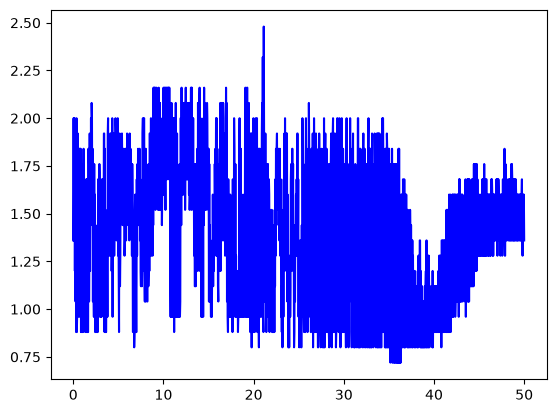

In [172]:
from scipy.signal import savgol_filter
from scipy.signal import find_peaks as fp
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("Newfile2.csv", skiprows=1)

volt = pd.to_numeric(df["Volt"])


num_points = 1400
x = np.linspace(0,50,num_points)
y = np.sin(x)
noise = np.random.random(size = num_points)-[0.5]
y_noise = y+noise

plt.plot(x,volt, color="blue", label="filter")

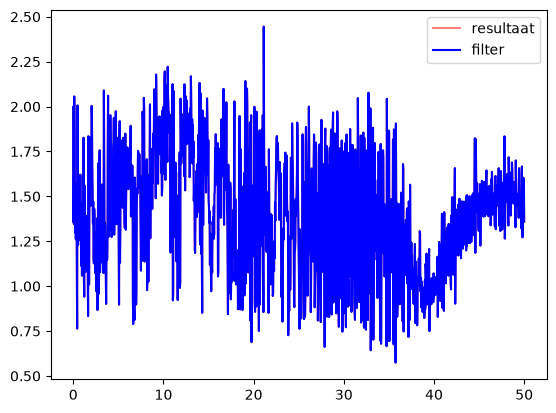

In [173]:
window_length = 15
poly_order = 13
volt_filter = savgol_filter(volt, window_length, poly_order)

plt.plot(x,volt_filter, alpha=0.5, color="red", label="resultaat")
plt.plot(x,volt_filter, color="blue", label="filter")
plt.legend()
plt.show()


Er zijn 363 franjes geteld.


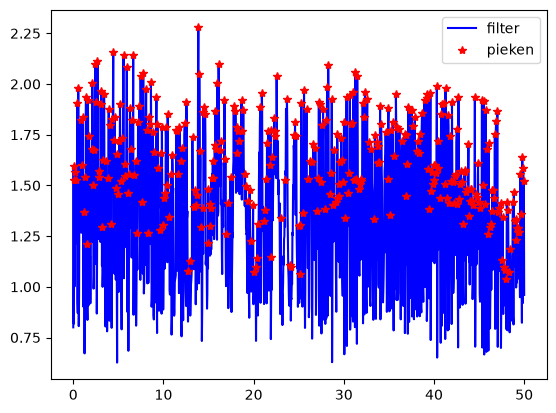

In [170]:
pieken, _ = fp(volt_filter, prominence=0.1, height=0.5)
plt.plot(x,volt_filter, color="blue", label="filter")
plt.plot(x[pieken], volt_filter[pieken], "*", color="red", label="pieken")
plt.legend()

print(f"Er zijn {len(pieken) - 1} franjes geteld.")

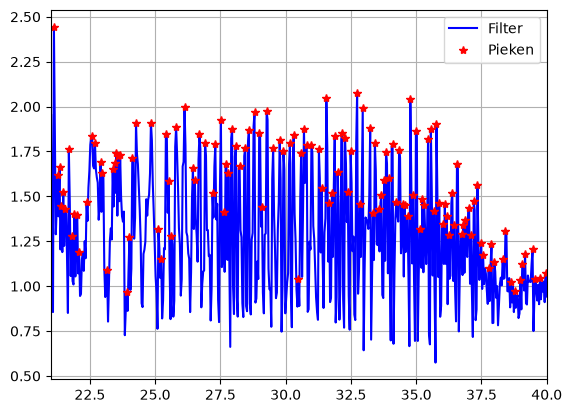

Er zijn 131 franjes geteld.


In [176]:


from scipy.signal import find_peaks as fp
import matplotlib.pyplot as plt
import numpy as np

# Selecteer alleen het gebied tussen x = 21 en x = 40
masker = (x >= 21) & (x <= 40)

x_filter = x[masker]
volt_filter_bijgewerkt = volt_filter[masker]

# Zoek pieken binnen dit gebied
pieken, _ = fp(
    volt_filter_bijgewerkt,
    prominence=0.1,
    height=0.5
)

# Plot het gefilterde gebied en de gevonden pieken
plt.plot(x_filter, volt_filter_bijgewerkt,
         color="blue", label="Filter")

plt.plot(x_filter[pieken], volt_filter_bijgewerkt[pieken],
         "*", color="red", label="Pieken")

plt.xlim(21, 40)
plt.legend()
plt.grid()
plt.show()

print(f"Er zijn {len(pieken) - 1} franjes geteld.")

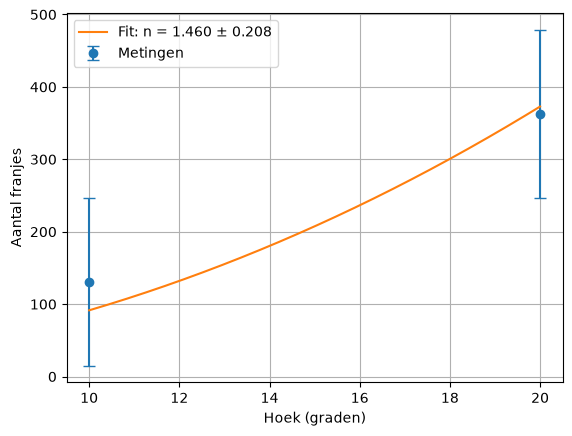

1.4602183760774419 ± 116.0


In [177]:
#brekingsindex berekenen
import numpy as np
import scipy.optimize as sp
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.signal import savgol_filter


#  constanten en de csv inlezen
d = 5000000
L = 528
hoek = np.array([10, 20])
franjes = np.array([131, 363])
fout_N =np.std(franjes)

# hoek naar radialen en de formule voor N
def N(i,n):
    i = np.deg2rad(i)
    return 2*d/L*np.abs(np.sqrt(n**2-np.sin(i)**2)-np.cos(i)+1-n)


# de curve fit maken
curve_1, curve_2 = sp.curve_fit(N, hoek, franjes, sigma=fout_N, absolute_sigma=True)

n_fit = curve_1[0]
fout_n = np.sqrt(curve_2[0, 0])

# de fit lijn gladder maken 
hoek_fit = np.linspace(min(hoek), max(hoek), 500)
franjes_fit = N(hoek_fit, n_fit)


# foutbalken aan de plot toevoegen
plt.errorbar(hoek,franjes,yerr=fout_N,fmt="o",capsize=4,label="Metingen")

# de fit weergeven inde plot
plt.plot(hoek_fit,franjes_fit,label=f"Fit: n = {n_fit:.3f} ± {fout_n:.3f}")

# plot mooier maken met legenda en as titels
plt.xlabel("Hoek (graden)")
plt.ylabel("Aantal franjes")
plt.legend()
plt.grid()

# de grafiek opslaan
plt.savefig("team_10_fit_plot.png", dpi=300)

# de grafiek laten zien
plt.show()

# de waarde van N met de fout printen
print(n_fit, "±", fout_N )

In [ ]:
#curve fit van brekingsindex over concentratie
concentratie([])
foutbrekingsindex = np.array([])
brekingsindexen= np.array([])

def model(a,x,b)
    y = a*x+b
    return y
popt, pcov = sp.curve_fit(model,concentratie, brekingsindexen, sigma = foutbrekingsindex, absolute_sigma=True)

a = popt[0]
fout_a=np.sqrt(pcov[0,0])
b= popt[1]

plt.errorbar(concentratie, brekingsindexen, yerr= foutbrekingsindex, fmt= "o", capsize = 4, label="metingen")

plt.plot(concentratie, brekingsindexen,label=f"Fit: n = {a:.3f} ± {fout_a:.3f}")

plt.xlabel("concentratie")
plt.ylabel("brekingsindexen")
plt.legend()
plt.grid()

plt.show()



In [ ]:
#concentratie berekenen met behulp van a en brekingsindex

C=n_fit/a+b

C_fout = np.sqrt((1/a+b)**2+(n_fit/a**2+b)**2
print(C "+-" C_fout)
